In [1]:
import Aarambam as Am
import numpy as np, matplotlib.pyplot as plt

In [2]:
plt.rcParams["axes.linewidth"]  = 1.0
plt.rcParams["xtick.major.size"]  = 3.5
plt.rcParams["xtick.minor.size"]  = 2
plt.rcParams["ytick.major.size"]  = 3.5
plt.rcParams["ytick.minor.size"]  = 2
plt.rcParams["xtick.direction"]  = "in"
plt.rcParams["ytick.direction"]  = "in"
plt.rcParams["legend.frameon"] = 'False'
plt.rcParams['figure.figsize'] = [10, 10]
plt.rc('text', usetex=False)
plt.rc('font', family='serif', size=22)

COLORS = ["f07167","219ebc","c767ac","E0A100","59a270", 'A2A1A5']
COLORS = ['#' + c if c[0] != '#' else c for c in COLORS ]

from cycler import cycler
plt.rcParams['axes.prop_cycle'] = cycler(color=COLORS)

# Decompose basis

In [3]:
# ----------------------------------------------------------------------
# Construct the binned decomposition.
#
# Binned_Nk:
#     Number of bins along each of k1, k2 and k3.
#
# Binned_filter:
#     Global interpolation on k1/k2 and cell-local interpolation on k3.
#
# Binned_adaptive_pilot_N:
#     Resolution of the pilot grid used to place the adaptive bin edges.
#     A value of 64 is convenient for interactive notebook tests.
# ----------------------------------------------------------------------
Unit = Am.utils.Decomposer(n_s = 0.96, Lbox = 1000, Nmax = 512, Binned_Nk = 20, 
                            Binned_adaptive_pilot_N = 64, Binned_filter = 'hybrid_cubic_k3cubic')

# Decompose the ScalarI template and write the C-readable tables.
coeff = Unit.go(Model = Am.models.ScalarI, Basis = Am.basis.binned.BasicBinnedDecompose, mass = 1, outdir = './')

INFO    | Aarambam.utils.C | Starting binned decomposition for ScalarI.
INFO    | Aarambam.utils.C | Built roughness-adaptive log grid: pilot_N=64, bins=(20, 20, 20).
INFO    | Aarambam.utils.C | k1: 20 bins over [6.283185e-03, 3.216991e+00].
INFO    | Aarambam.utils.C | k2: 20 bins over [6.283185e-03, 3.216991e+00].
INFO    | Aarambam.utils.C | k3: 20 bins over [6.283185e-03, 3.216991e+00].


Binning IC kernel:   0%|          | 0/400 [00:00<?, ?it/s]

INFO    | Aarambam.utils.C | Finished binned decomposition: shape=(20, 20, 20), filter=hybrid.
INFO    | Aarambam.utils.C | Binned kernel tables written to ./.


# Plot templates

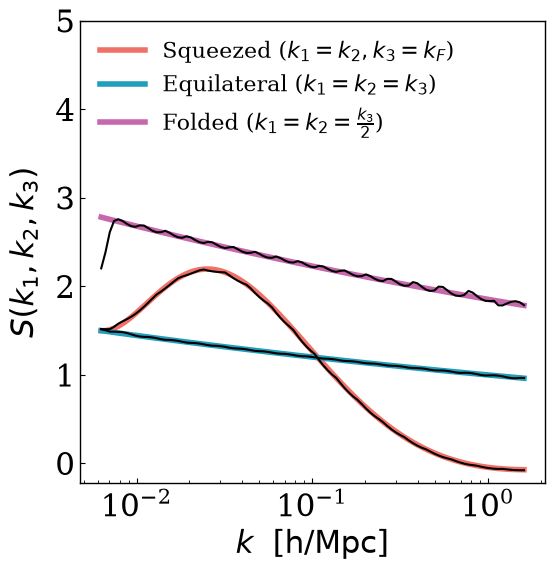

In [4]:
plt.figure(figsize = (6,6))
plt.xscale('log')
Input  = coeff['S_original'].T
Output = coeff['S_apprx'].T
k_in   = coeff['kbin']

for j, label in enumerate(['Squeezed', 'Equilateral', 'Folded']):
    plt.plot(k_in, Input[j], label = j, lw = 4)
    plt.plot(k_in, Output[j], color = 'k', zorder = 10000)
        
plt.legend([plt.plot([], [], lw = 4, color = f'C{i}')[0] for i in range(3)], 
            [r'Squeezed ($k_1 = k_2, k_3 = k_F$)', r'Equilateral ($k_1 = k_2 = k_3$)', r'Folded ($k_1 = k_2 = \frac{k_3}{2}$)'],
            fontsize = 16, ncol = 1, loc = 'upper left')

plt.ylabel(r'$S(k_1,k_2,k_3)$', size = 22, labelpad = 10)
plt.xlabel(r'$k$  [$\rm h/Mpc$]', size = 22)
plt.ylim(None, 5)
plt.show()